# Olist delivery analysis with SQL

This notebook starts with the tables, then follows orders from purchase to delivery. The questions are: how common are delays, where do they happen, and how do they relate to dispatch timing and customer reviews?

**Skills:** SQL, data analysis, relational databases.

The source is the [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). SQL does the calculations; Python displays the tables and charts.

## 1. Open the database

Run this notebook from the project folder. If the database is not there yet, download the six CSVs listed in the README and run `python3 scripts/load_data.py` first.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

connection = sqlite3.connect("file:data/olist.sqlite?mode=ro", uri=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)
pd.options.display.float_format = "{:,.2f}".format

# Use this small helper to show SQL results as tables.
def sql(query):
    return pd.read_sql_query(query, connection)

## 2. What is in the database?

There are six source tables. First, count their rows. Different row counts are expected: an order can contain several items and payment records.

In [2]:
sql("""
SELECT 'customers' AS table_name, COUNT(*) AS rows FROM customers
UNION ALL
SELECT 'orders', COUNT(*) FROM orders
UNION ALL
SELECT 'order_items', COUNT(*) FROM order_items
UNION ALL
SELECT 'sellers', COUNT(*) FROM sellers
UNION ALL
SELECT 'payments', COUNT(*) FROM payments
UNION ALL
SELECT 'reviews', COUNT(*) FROM reviews;
""")

,table_name,rows
0,customers,99441
1,orders,99441
2,order_items,112650
3,sellers,3095
4,payments,103886
5,reviews,99224


There are 99,441 orders and 112,650 item rows. So joining items to orders will not leave one row per order. Before doing any totals, it helps to look at what each table contains.

### Orders

One row is one order. The dates describe purchase, payment approval, carrier handover, customer delivery and the estimated delivery date. Missing dates can reflect an order that did not complete the whole process.

In [3]:
sql("""
SELECT *
FROM orders
ORDER BY order_id
LIMIT 5;
""")

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15 00:00:00
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17 00:00:00


### Customers

`customer_id` links to an order's customer record. `customer_unique_id` identifies the same customer across different orders. The state and city are useful for comparing delivery destinations.

In [4]:
sql("""
SELECT *
FROM customers
ORDER BY customer_id
LIMIT 5;
""")

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,00012a2ce6f8dcda20d059ce98491703,248ffe10d632bebe4f7267f1f44844c9,06273,osasco,SP
1,000161a058600d5901f007fab4c27140,b0015e09bb4b6e47c52844fab5fb6638,35550,itapecerica,MG
2,0001fd6190edaaf884bcaf3d49edf079,94b11d37cd61cb2994a194d11f89682b,29830,nova venecia,ES
3,0002414f95344307404f0ace7a26f1d5,4893ad4ea28b2c5b3ddf4e82e79db9e6,39664,mendonca,MG
4,000379cdec625522490c315e70c7a9fb,0b83f73b19c2019e182fd552c048a22c,04841,sao paulo,SP


### Order items

An order can have several rows here. `order_item_id` numbers the items within the order; `seller_id` identifies the seller. Price and freight are recorded per item, in Brazilian reais (BRL).

In [5]:
sql("""
SELECT *
FROM order_items
ORDER BY order_id, order_item_id
LIMIT 5;
""")

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


### Sellers

This table gives the seller's location. Joining it to order items lets us compare the origin and destination states.

In [6]:
sql("""
SELECT *
FROM sellers
ORDER BY seller_id
LIMIT 5;
""")

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,0015a82c2db000af6aaaf3ae2ecb0532,09080,santo andre,SP
1,001cca7ae9ae17fb1caed9dfb1094831,29156,cariacica,ES
2,001e6ad469a905060d959994f1b41e4f,24754,sao goncalo,RJ
3,002100f778ceb8431b7a1020ff7ab48f,14405,franca,SP
4,003554e2dce176b5555353e4f3555ac8,74565,goiania,GO


### Payments

One order can have several payment records. `payment_sequential` distinguishes those records, while `payment_installments` is the number of installments for that payment. They mean different things.

In [7]:
sql("""
SELECT *
FROM payments
ORDER BY order_id, payment_sequential
LIMIT 5;
""")

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,credit_card,2,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,credit_card,3,259.83
2,000229ec398224ef6ca0657da4fc703e,1,credit_card,5,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,credit_card,2,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,credit_card,3,218.04


### Reviews

The source includes review scores from 1 to 5. Some orders have more than one review row. The import keeps the dates and scores; review text is not used in this project. `source_row` is a row number added during import.

In [8]:
sql("""
SELECT *
FROM reviews
ORDER BY source_row
LIMIT 5;
""")

,source_row,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
0,1,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,2018-01-18 00:00:00,2018-01-18 21:46:59
1,2,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,2018-03-10 00:00:00,2018-03-11 03:05:13
2,3,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,2018-02-17 00:00:00,2018-02-18 14:36:24
3,4,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,2017-04-21 00:00:00,2017-04-21 22:02:06
4,5,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,2018-03-01 00:00:00,2018-03-02 10:26:53


## 3. How the tables connect

A **primary key (PK)** identifies a row. A **foreign key (FK)** points to a row in another table. For example, `orders.customer_id` points to `customers.customer_id`.

The arrows below show how parent records connect to child records. The order is the central record; items, payments and reviews can each have several rows for that order.

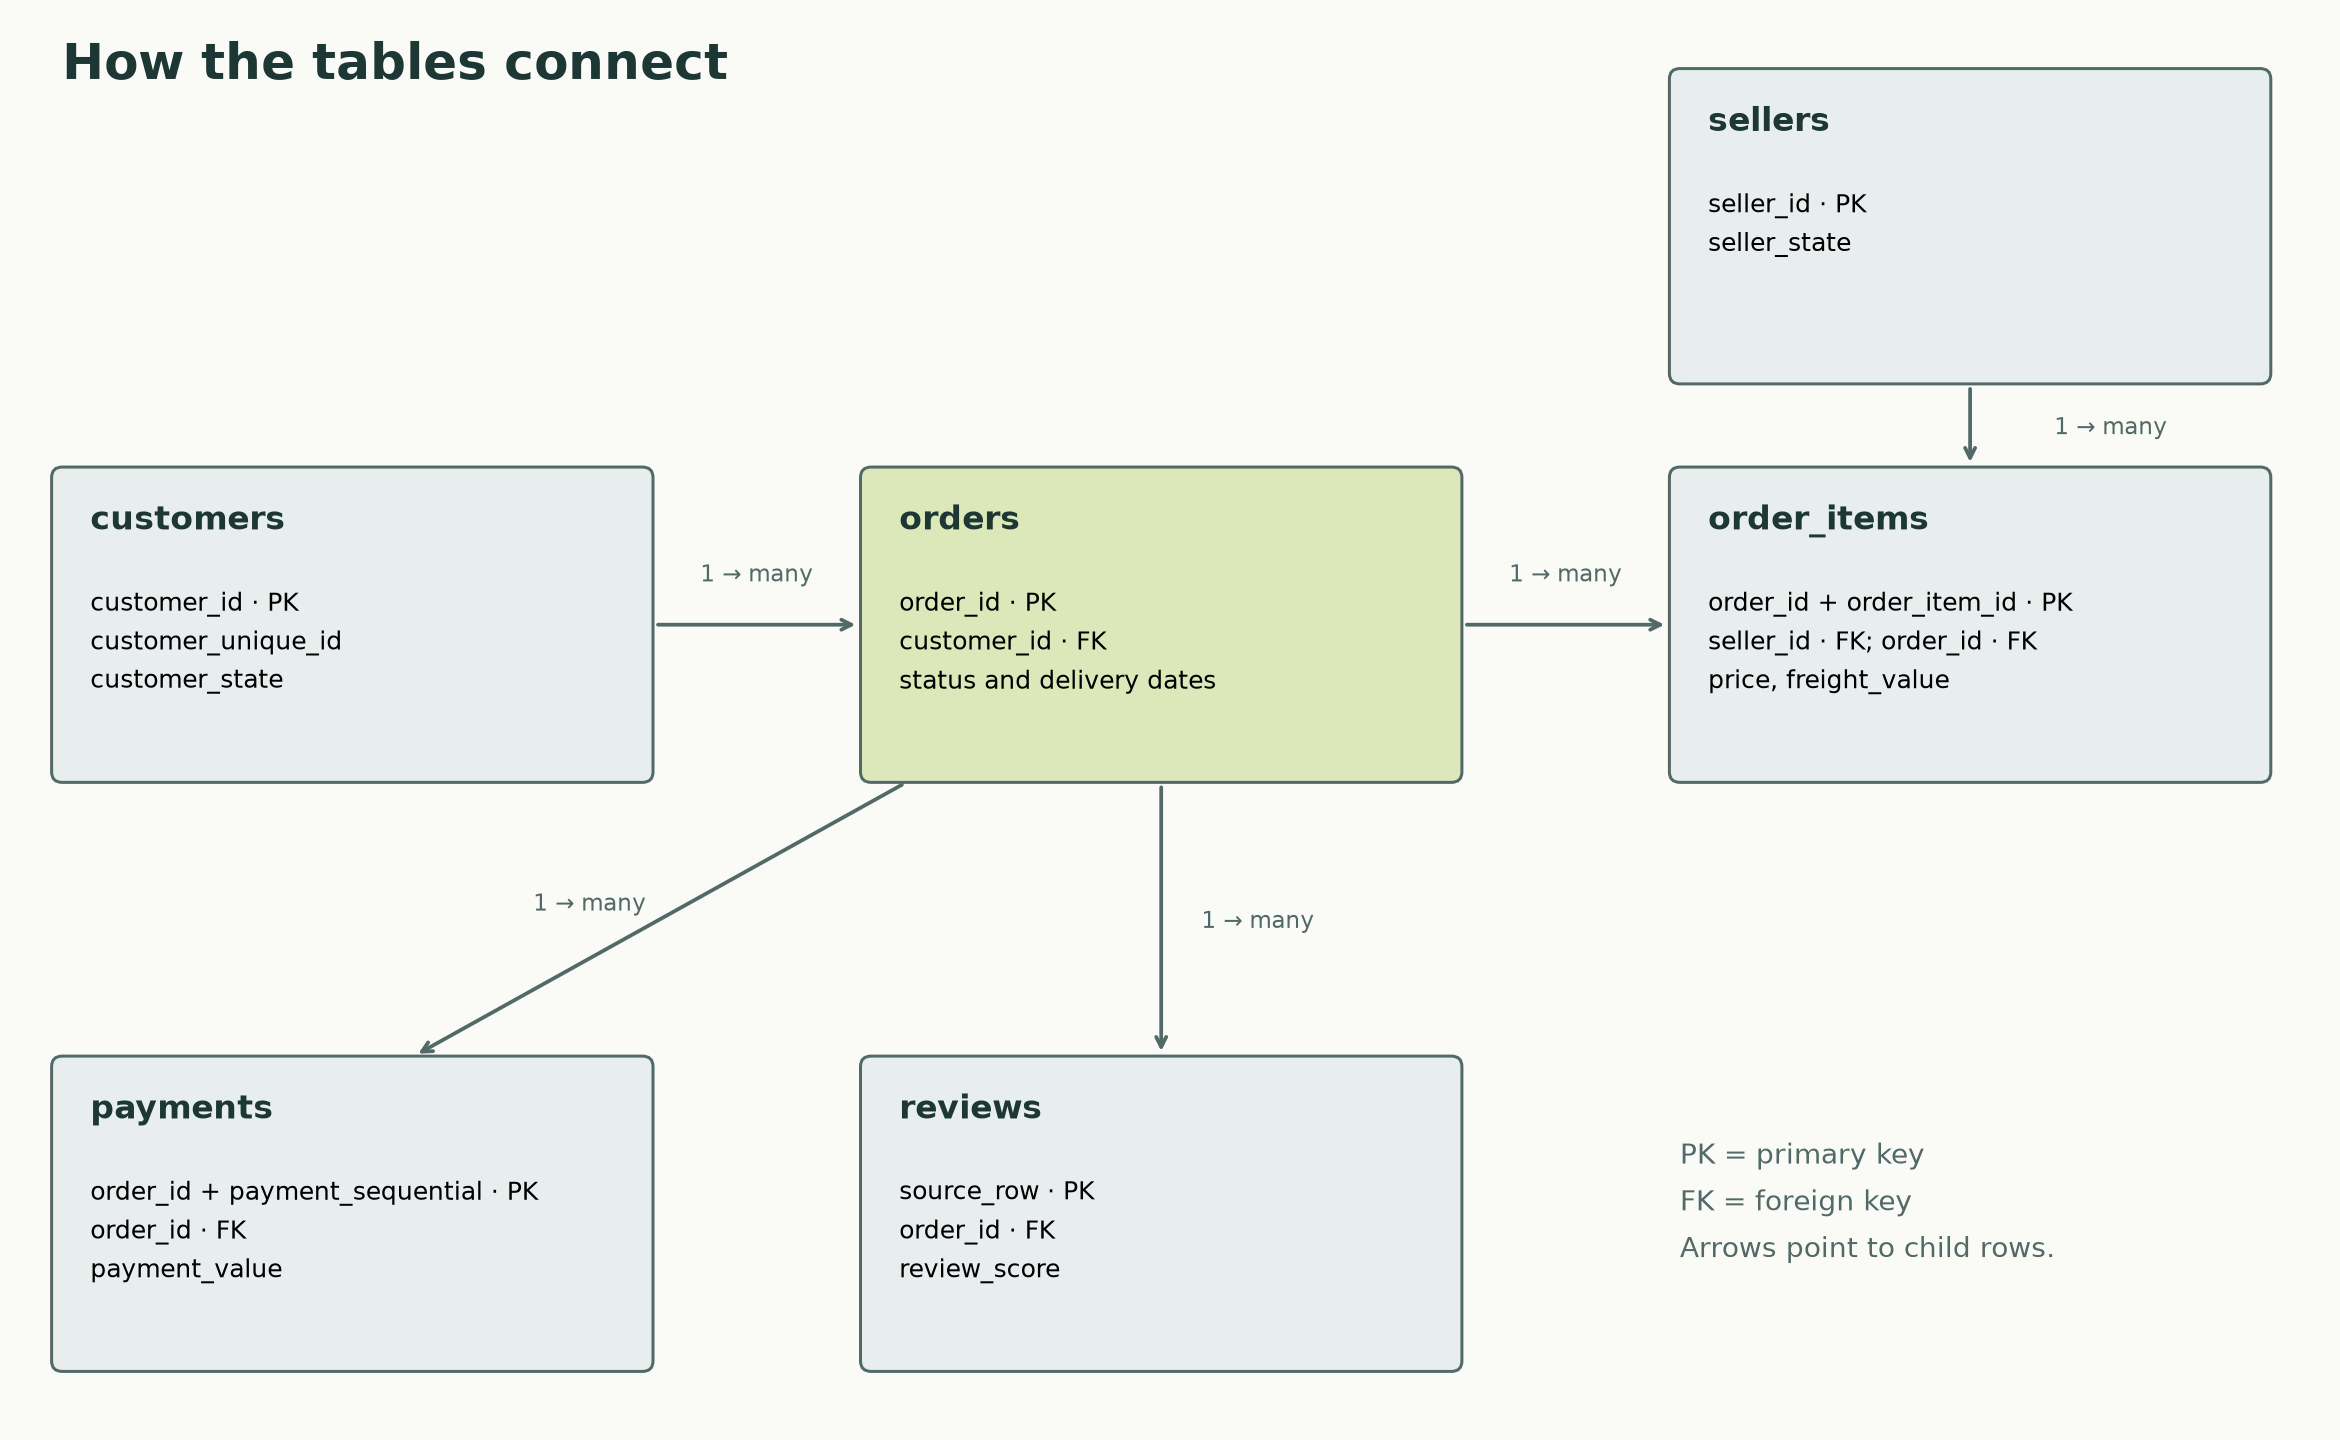

In [9]:
display(Image(filename="docs/schema.png"))

The customer link uses `customer_id`, not `customer_unique_id`. In this snapshot, each order has its own customer record; repeat buyers share a `customer_unique_id`.

Start with a simple join: add the customer's state to each order.

In [10]:
sql("""
SELECT
    o.order_id,
    o.order_status,
    c.customer_state,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
ORDER BY o.order_id
LIMIT 5;
""")

,order_id,order_status,customer_state,order_purchase_timestamp,order_delivered_customer_date
0,00010242fe8c5a6d1ba2dd792cb16214,delivered,RJ,2017-09-13 08:59:02,2017-09-20 23:43:48
1,00018f77f2f0320c557190d7a144bdd3,delivered,SP,2017-04-26 10:53:06,2017-05-12 16:04:24
2,000229ec398224ef6ca0657da4fc703e,delivered,MG,2018-01-14 14:33:31,2018-01-22 13:19:16
3,00024acbcdf0a6daa1e931b038114c75,delivered,SP,2018-08-08 10:00:35,2018-08-14 13:32:39
4,00042b26cf59d7ce69dfabb4e55b4fd9,delivered,SP,2017-02-04 13:57:51,2017-03-01 16:42:31


This join keeps the order as the unit of analysis. The item, review and payment joins need more care because those tables can have multiple matching rows.

## 4. Dates, statuses and missing values

Before measuring delivery, check when the orders were placed.

In [11]:
sql("""
SELECT
    MIN(order_purchase_timestamp) AS first_purchase,
    MAX(order_purchase_timestamp) AS last_purchase
FROM orders;
""")

,first_purchase,last_purchase
0,2016-09-04 21:15:19,2018-10-17 17:30:18


The data run from September 2016 to October 2018. This is a historical dataset, and the first and last months are partial.

What happened to the orders?

In [12]:
sql("""
SELECT
    order_status,
    COUNT(*) AS orders,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM orders), 2) AS share_pct
FROM orders
GROUP BY order_status
ORDER BY orders DESC;
""")

,order_status,orders,share_pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


Most orders are marked delivered. A late-delivery rate needs an actual delivery date and a promised date, so canceled and unresolved orders will not be in that calculation.

In [13]:
sql("""
SELECT
    COUNT(*) AS orders_marked_delivered,
    SUM(order_delivered_customer_date IS NULL) AS missing_delivery_date,
    SUM(order_estimated_delivery_date IS NULL) AS missing_estimate
FROM orders
WHERE order_status = 'delivered';
""")

,orders_marked_delivered,missing_delivery_date,missing_estimate
0,96478,8,0


Eight orders are marked delivered but have no delivery date. Leave these out rather than guess when they arrived.

### Defining a late delivery

An order is late if its **delivery date is after the estimated date**. A delivery at 8 pm on the promised day is still on time.

The database already contains a saved query, or **view**, called `order_delivery`. It joins orders to customers and adds three fields:

- `is_eligible`: delivered status, usable dates and no delivery before purchase;
- `is_late`: 1 for late, 0 for on time;
- `delivery_days`: elapsed days from purchase to delivery.

This is the date comparison used by the view:

```sql
CASE
    WHEN date(order_delivered_customer_date) > date(order_estimated_delivery_date)
    THEN 1
    ELSE 0
END AS is_late
```

Its full definition is in [sql/schema.sql](sql/schema.sql).

## 5. How common are late deliveries?

In [14]:
overall = sql("""
SELECT
    COUNT(*) AS eligible_orders,
    SUM(is_late) AS late_orders,
    ROUND(100.0 * AVG(is_late), 2) AS late_pct,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days
FROM order_delivery
WHERE is_eligible = 1;
""")
overall

,eligible_orders,late_orders,late_pct,avg_delivery_days
0,96470,6534,6.77,12.56


**6,534 of 96,470 eligible orders arrived late: 6.77%.** This is the overall starting point. Next, compare purchase months to see whether that average hides large differences.

## 6. Does the late rate change by month?

In [15]:
monthly = sql("""
WITH cutoff AS (
    SELECT date(MAX(order_purchase_timestamp), 'start of month') AS month_start
    FROM orders
)
SELECT
    strftime('%Y-%m', order_purchase_timestamp) AS purchase_month,
    COUNT(*) AS eligible_orders,
    SUM(is_late) AS late_orders,
    ROUND(100.0 * AVG(is_late), 2) AS late_pct
FROM order_delivery
WHERE is_eligible = 1
  AND date(order_purchase_timestamp) < (SELECT month_start FROM cutoff)
GROUP BY purchase_month
ORDER BY purchase_month;
""")
monthly

,purchase_month,eligible_orders,late_orders,late_pct
0,2016-09,1,1,100.00
1,2016-10,265,2,0.75
2,2016-12,1,0,0.00
3,2017-01,750,22,2.93
4,2017-02,1653,49,2.96
5,2017-03,2546,116,4.56
6,2017-04,2303,151,6.56
7,2017-05,3545,106,2.99
8,2017-06,3135,95,3.03
9,2017-07,3872,108,2.79


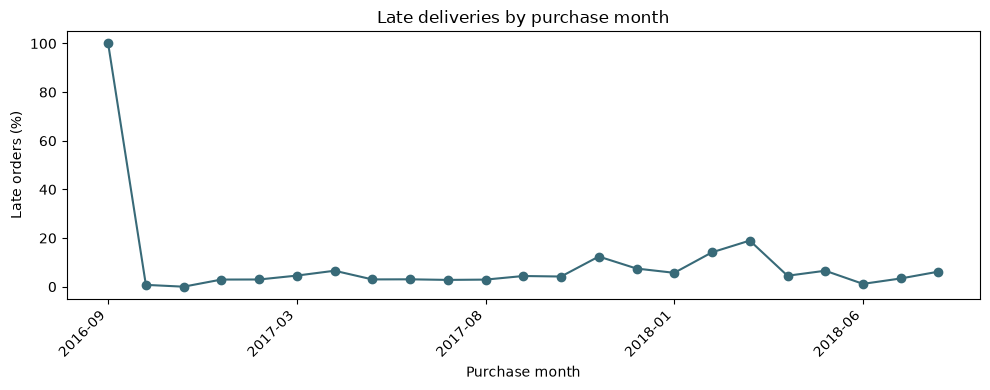

In [16]:
ax = monthly.plot(
    x="purchase_month", y="late_pct", kind="line",
    marker="o", color="#386a78", figsize=(10, 4), legend=False
)
ax.set(title="Late deliveries by purchase month", xlabel="Purchase month", ylabel="Late orders (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

March 2018 has a late rate of **18.96% across 7,003 eligible orders**, well above the overall rate. The query leaves out the latest purchase month, but recent cohorts can still be missing unresolved orders. This chart does not establish what caused the changes.

## 7. Which destinations have the highest late rates?

Compare customer states with at least 100 eligible orders. This keeps very small groups out of the ranking.

In [17]:
states = sql("""
SELECT
    customer_state,
    COUNT(*) AS eligible_orders,
    SUM(is_late) AS late_orders,
    ROUND(100.0 * AVG(is_late), 2) AS late_pct,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days
FROM order_delivery
WHERE is_eligible = 1
GROUP BY customer_state
HAVING COUNT(*) >= 100
ORDER BY late_pct DESC, customer_state;
""")
states.head(10)

,customer_state,eligible_orders,late_orders,late_pct,avg_delivery_days
0,AL,397,85,21.41,24.54
1,MA,717,125,17.43,21.57
2,SE,335,51,15.22,21.52
3,PI,476,66,13.87,19.46
4,CE,1279,176,13.76,21.27
5,BA,3256,396,12.16,19.34
6,RJ,12350,1495,12.11,15.31
7,PA,946,106,11.21,23.77
8,ES,1995,214,10.73,15.79
9,PB,517,54,10.44,20.43


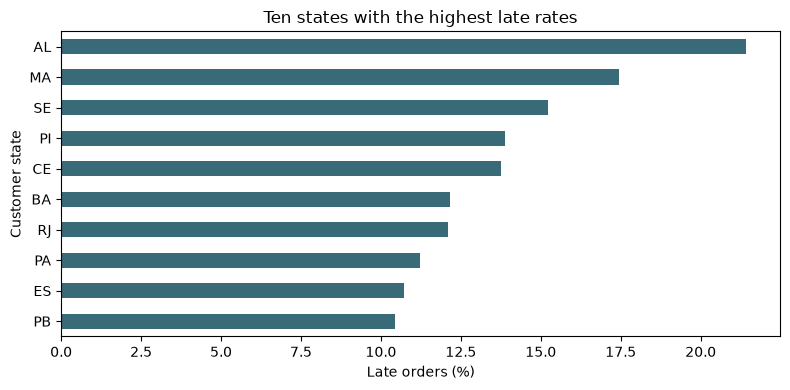

In [18]:
top_states = states.head(10).sort_values("late_pct")
ax = top_states.plot(
    x="customer_state", y="late_pct", kind="barh",
    color="#386a78", figsize=(8, 4), legend=False
)
ax.set(title="Ten states with the highest late rates", xlabel="Late orders (%)", ylabel="Customer state")
plt.tight_layout()
plt.show()

Alagoas (AL) has the highest rate in this group: **21.41%, or 85 of 397 orders**. But a high percentage does not necessarily mean the largest number of affected customers. Check the number of late orders as well.

In [19]:
delay_share = sql("""
WITH state_totals AS (
    SELECT customer_state, COUNT(*) AS late_orders
    FROM order_delivery
    WHERE is_eligible = 1 AND is_late = 1
    GROUP BY customer_state
)
SELECT
    customer_state,
    late_orders,
    ROUND(100.0 * late_orders / SUM(late_orders) OVER (), 2) AS share_pct,
    ROUND(
        100.0 * SUM(late_orders) OVER (
            ORDER BY late_orders DESC, customer_state
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) / SUM(late_orders) OVER (), 2
    ) AS cumulative_share_pct
FROM state_totals
ORDER BY late_orders DESC, customer_state;
""")
delay_share.head(10)

,customer_state,late_orders,share_pct,cumulative_share_pct
0,SP,1820,27.85,27.85
1,RJ,1495,22.88,50.73
2,MG,519,7.94,58.68
3,BA,396,6.06,64.74
4,RS,325,4.97,69.71
5,SC,291,4.45,74.17
6,ES,214,3.28,77.44
7,PR,199,3.05,80.49
8,CE,176,2.69,83.18
9,PE,153,2.34,85.52


São Paulo (SP) and Rio de Janeiro (RJ) account for **50.73% of all late orders**. AL stands out for reliability; SP and RJ stand out for volume. These suggest different priorities for a closer investigation.

## 8. Is late dispatch associated with late delivery?

`shipping_limit_date` is stored per item, while carrier handover is stored per order. Use orders where all items share the same shipping deadline, then compare the handover timestamp with that deadline.

In [20]:
dispatch = sql("""
WITH deadlines AS (
    SELECT order_id, MIN(shipping_limit_date) AS deadline
    FROM order_items
    GROUP BY order_id
    HAVING COUNT(shipping_limit_date) = COUNT(*)
       AND MIN(shipping_limit_date) = MAX(shipping_limit_date)
),
dispatch_groups AS (
    SELECT
        d.is_late,
        CASE
            WHEN julianday(d.order_delivered_carrier_date) > julianday(i.deadline)
            THEN 'after_deadline'
            ELSE 'within_deadline'
        END AS dispatch_group
    FROM order_delivery d
    JOIN deadlines i USING (order_id)
    WHERE d.is_eligible = 1
      AND julianday(d.order_delivered_carrier_date)
          BETWEEN julianday(d.order_purchase_timestamp)
              AND julianday(d.order_delivered_customer_date)
)
SELECT
    dispatch_group,
    COUNT(*) AS eligible_orders,
    SUM(is_late) AS late_orders,
    ROUND(100.0 * AVG(is_late), 2) AS late_pct
FROM dispatch_groups
GROUP BY dispatch_group
ORDER BY dispatch_group;
""")
dispatch

,dispatch_group,eligible_orders,late_orders,late_pct
0,after_deadline,8695,1814,20.86
1,within_deadline,87257,4717,5.41


The late rate is **20.86% after a missed shipping deadline**, compared with **5.41% within the deadline**. Dispatch timing looks worth tracking. Route length and delivery promises could also differ between these groups.

## 9. Which sellers are associated with more late deliveries?

Keep single-seller orders so that one delivery is not assigned to several sellers. As with states, require at least 100 eligible orders.

In [21]:
seller_rates = sql("""
WITH single_seller AS (
    SELECT order_id, MIN(seller_id) AS seller_id
    FROM order_items
    GROUP BY order_id
    HAVING COUNT(DISTINCT seller_id) = 1
)
SELECT
    i.seller_id,
    s.seller_state,
    COUNT(*) AS eligible_orders,
    SUM(d.is_late) AS late_orders,
    ROUND(100.0 * AVG(d.is_late), 2) AS late_pct
FROM single_seller i
JOIN order_delivery d USING (order_id)
JOIN sellers s USING (seller_id)
WHERE d.is_eligible = 1
GROUP BY i.seller_id, s.seller_state
HAVING COUNT(*) >= 100
ORDER BY late_pct DESC, i.seller_id;
""")
seller_rates.head(10)

,seller_id,seller_state,eligible_orders,late_orders,late_pct
0,06a2c3af7b3aee5d69171b0e14f0ee87,MA,388,74,19.07
1,88460e8ebdecbfecb5f9601833981930,PR,227,42,18.50
2,1ca7077d890b907f89be8c954a02686a,SP,106,18,16.98
3,e5a3438891c0bfdb9394643f95273d8e,SP,213,34,15.96
4,cd68562d3f44870c08922d380acae552,SP,122,19,15.57
5,2c9e548be18521d1c43cde1c582c6de8,SP,123,19,15.45
6,8160255418d5aaa7dbdc9f4c64ebda44,SP,355,51,14.37
7,f7ba60f8c3f99e7ee4042fdef03b70c4,SP,213,30,14.08
8,431af27f296bc6519d890aa5a05fdb11,SP,114,16,14.04
9,7ad32824caee82087b3e2e5f33b1bf32,SP,140,19,13.57


The first seller has **74 late orders out of 388 (19.07%)**. This identifies orders to investigate; it does not tell us whether the seller or a later delivery stage caused the delay.

## 10. What do customer reviews show?

First check how many orders have multiple review rows.

In [22]:
sql("""
SELECT COUNT(*) AS orders_with_multiple_reviews
FROM (
    SELECT order_id
    FROM reviews
    GROUP BY order_id
    HAVING COUNT(*) > 1
);
""")

,orders_with_multiple_reviews
0,547


There are **547** such orders. The `latest_reviews` view keeps one review per order using this ordering:

```sql
ROW_NUMBER() OVER (
    PARTITION BY order_id
    ORDER BY review_creation_date DESC, review_answer_timestamp DESC,
             review_id DESC, source_row DESC
) AS review_rank
```

Only `review_rank = 1` is kept. Now join those scores to the delivery results.

In [23]:
review_scores = sql("""
SELECT
    CASE d.is_late WHEN 1 THEN 'late' ELSE 'on_time' END AS delivery_group,
    COUNT(*) AS reviewed_orders,
    ROUND(AVG(r.review_score), 2) AS avg_review_score,
    ROUND(100.0 * AVG(r.review_score <= 2), 2) AS low_score_pct
FROM order_delivery d
JOIN latest_reviews r USING (order_id)
WHERE d.is_eligible = 1
  AND r.review_score IS NOT NULL
GROUP BY d.is_late
ORDER BY d.is_late;
""")
review_scores

,delivery_group,reviewed_orders,avg_review_score,low_score_pct
0,on_time,89443,4.29,9.27
1,late,6381,2.27,62.40


The average score is **4.29 for on-time orders** and **2.27 for late orders**. Low scores (1 or 2) are also much more common for late orders. Product problems can affect the score too, and some reviews were submitted before delivery. Review text would help explain the complaints.

## 11. How do freight charges differ by route?

Compare same-state and interstate orders. Use single-seller orders to identify the origin, and sum item values before joining to orders.

In [24]:
freight = sql("""
WITH item_totals AS (
    SELECT
        order_id,
        MIN(seller_id) AS seller_id,
        SUM(price) AS goods_value,
        SUM(freight_value) AS freight_value
    FROM order_items
    GROUP BY order_id
    HAVING COUNT(DISTINCT seller_id) = 1
),
routes AS (
    SELECT
        i.goods_value,
        i.freight_value,
        CASE
            WHEN s.seller_state = d.customer_state THEN 'same_state'
            ELSE 'interstate'
        END AS route_type
    FROM item_totals i
    JOIN order_delivery d USING (order_id)
    JOIN sellers s USING (seller_id)
    WHERE d.is_eligible = 1 AND i.goods_value > 0
      AND s.seller_state IS NOT NULL AND d.customer_state IS NOT NULL
)
SELECT
    route_type,
    COUNT(*) AS eligible_orders,
    ROUND(AVG(freight_value), 2) AS avg_freight_brl,
    ROUND(100.0 * SUM(freight_value) / SUM(goods_value), 2) AS freight_to_goods_pct
FROM routes
GROUP BY route_type
ORDER BY route_type;
""")
freight

,route_type,eligible_orders,avg_freight_brl,freight_to_goods_pct
0,interstate,60961,26.55,18.18
1,same_state,34234,15.19,12.84


Average freight is **BRL 26.55 between states**, versus **BRL 15.19 within a state**. Freight is 18.18% and 12.84% of goods value, respectively. This ratio uses totals rather than the average of individual order percentages. These are recorded charges, not the carrier's operating costs.

## 12. Do payments match the order totals?

One last check brings together items and payments. Both tables can have several rows per order, so joining them directly would inflate totals. Sum each table first, then join the two totals to orders.

In [25]:
payments = sql("""
WITH item_totals AS (
    SELECT order_id, ROUND(SUM(price + freight_value), 2) AS order_value
    FROM order_items
    GROUP BY order_id
),
payment_totals AS (
    SELECT order_id, ROUND(SUM(payment_value), 2) AS paid_value
    FROM payments
    GROUP BY order_id
),
reconciled AS (
    SELECT
        CASE
            WHEN i.order_id IS NULL THEN 'missing_items'
            WHEN p.order_id IS NULL THEN 'missing_payment'
            WHEN ABS(i.order_value - p.paid_value) > 0.02 THEN 'difference_over_0_02_brl'
            ELSE 'matched_within_0_02_brl'
        END AS reconciliation_status
    FROM orders o
    LEFT JOIN item_totals i USING (order_id)
    LEFT JOIN payment_totals p USING (order_id)
)
SELECT reconciliation_status, COUNT(*) AS orders
FROM reconciled
GROUP BY reconciliation_status
ORDER BY orders DESC;
""")
payments

,reconciliation_status,orders
0,matched_within_0_02_brl,98385
1,missing_items,775
2,difference_over_0_02_brl,280
3,missing_payment,1


**98,385 orders match within BRL 0.02.** There are 280 orders outside that tolerance, 775 without item rows and one without a payment row. These differences would need a closer look before drawing accounting conclusions.

## 13. Conclusions

The overall late rate is 6.77%, but the regional results show why that average is only a starting point. AL has a high late rate, while SP and RJ account for about half of late orders by volume.

Missed dispatch deadlines are associated with more late deliveries, and late orders receive much lower review scores. A useful next step would be to examine high-volume routes into SP and RJ and split the dispatch results by route and delivery promise.

The analysis includes completed orders with usable dates. It does not capture every unresolved order, and it does not adjust for distance or product mix. Parcel-level events and carrier information would help separate the stages of a delay.

In [26]:
connection.close()